# CSET485 – AI and Society – Assignment #1
Rajyavardhan Singh Rathore | S24CSEU2172

COMPAS dataset, random_state = 172.

In [1]:
# setup and helper functions
import json
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

warnings.filterwarnings("ignore")

SEED = 172
DATA_PATH = "compas-scores-two-years.csv"
DATA_URL = "https://github.com/propublica/compas-analysis/raw/master/compas-scores-two-years.csv"

os.makedirs("figures", exist_ok=True)
os.makedirs("tables", exist_ok=True)

R = {}

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
})


def sigmoid(z):
    return 1 / (1 + np.exp(-z))


def logit_fit(X, y, iters=100):
    X = np.column_stack([np.ones(len(X)), np.asarray(X, float)])
    y = np.asarray(y, float)
    b = np.zeros(X.shape[1])

    for _ in range(iters):
        p = sigmoid(X @ b)
        W = p * (1 - p)
        step = np.linalg.solve(X.T @ (X * W[:, None]), X.T @ (y - p))
        b = b + step
        if np.abs(step).max() < 1e-10:
            break

    p = sigmoid(X @ b)
    W = p * (1 - p)
    se = np.sqrt(np.diag(np.linalg.inv(X.T @ (X * W[:, None]))))
    ll = float(np.sum(y * np.log(p) + (1 - y) * np.log(1 - p)))

    return dict(
        b=b,
        se=se,
        z=b / se,
        p=2 * stats.norm.sf(abs(b / se)),
        lo=b - 1.96 * se,
        hi=b + 1.96 * se,
        ll=ll,
    )


def logit_predict(fit, X):
    X = np.column_stack([np.ones(len(X)), np.asarray(X, float)])
    return sigmoid(X @ fit["b"])

## Part 0 – Preprocessing

In [2]:
# part 0: load data
try:
    raw = pd.read_csv(DATA_PATH)
except Exception:
    raw = pd.read_csv(DATA_URL)
R["n_raw"] = len(raw)

# part 0: row filters
steps = [
    ("days_b_screening_arrest missing or outside [-30, 30]",
     lambda d: d["days_b_screening_arrest"].between(-30, 30)),
    ("is_recid == -1 (outcome not recorded)",
     lambda d: d["is_recid"] != -1),
    ("c_charge_degree == 'O' (ordinary traffic offence)",
     lambda d: d["c_charge_degree"] != "O"),
    ("score_text == 'N/A'",
     lambda d: d["score_text"] != "N/A"),
]

df = raw.copy()
filt_rows = []
for name, rule in steps:
    before = len(df)
    df = df[rule(df)]
    filt_rows.append((name, before - len(df), len(df)))
df = df.reset_index(drop=True)

filt_tbl = pd.DataFrame(filt_rows, columns=["filter", "rows_removed", "rows_remaining"])
print(filt_tbl.to_string(index=False))
R["n_clean"] = len(df)
R["filters"] = filt_rows
R["raw_missing_days_b"] = int(raw["days_b_screening_arrest"].isna().sum())

# part 0: encoding and missing values
FEATS = ["age", "sex_male", "priors_count", "juv_fel_count", "juv_misd_count", "juv_other_count", "charge_felony"]
Y_CLS = "two_year_recid"
Y_REG = "decile_score"

df["sex_male"] = (df["sex"] == "Male").astype(int)
df["charge_felony"] = (df["c_charge_degree"] == "F").astype(int)
df["race_aa"] = (df["race"] == "African-American").astype(int)
df["race_cauc"] = (df["race"] == "Caucasian").astype(int)
df["race_hisp"] = (df["race"] == "Hispanic").astype(int)
df["race_other"] = df["race"].isin(["Other", "Asian", "Native American"]).astype(int)

miss = df[FEATS + [Y_CLS, Y_REG, "race"]].isna().sum()
print("\nMissing values after filtering:\n", miss.to_string())
R["missing_after"] = int(miss.sum())

# part 0: outliers
out_rows = []
for c in ["age", "priors_count", "juv_fel_count", "juv_misd_count", "juv_other_count"]:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    upper = q3 + 1.5 * iqr
    lower = q1 - 1.5 * iqr
    is_out = (df[c] > upper) | (df[c] < lower)
    out_rows.append((c, df[c].min(), df[c].max(), int(is_out.sum()), round(100 * is_out.mean(), 1)))

out_tbl = pd.DataFrame(out_rows, columns=["feature", "min", "max", "n_outliers_IQR", "pct_outliers"])
print("\n", out_tbl.to_string(index=False))
R["outliers"] = out_rows
R["race_counts"] = df["race"].value_counts().to_dict()
R["base_rate"] = float(df[Y_CLS].mean())
R["sex_counts"] = df["sex"].value_counts().to_dict()

                                              filter  rows_removed  rows_remaining
days_b_screening_arrest missing or outside [-30, 30]          1042            6172
               is_recid == -1 (outcome not recorded)             0            6172
   c_charge_degree == 'O' (ordinary traffic offence)             0            6172
                                 score_text == 'N/A'             0            6172

Missing values after filtering:
 age                0
sex_male           0
priors_count       0
juv_fel_count      0
juv_misd_count     0
juv_other_count    0
charge_felony      0
two_year_recid     0
decile_score       0
race               0

         feature  min  max  n_outliers_IQR  pct_outliers
            age   18   96              51           0.8
   priors_count    0   38             492           8.0
  juv_fel_count    0   20             208           3.4
 juv_misd_count    0   13             352           5.7
juv_other_count    0    9             461           7.5

## Part 1 – Build

scaling max |dp|: 2.220446049250313e-16 | sklearn max |dp|: 9.110973251647003e-05 | acc raw/capped: 0.6787257019438445 0.677645788336933
        feature  OLS_coef  OLS_se  Logit_coef  Logit_se  Logit_p  Logit_OR
      intercept    6.8155  0.1341      0.3933    0.1384   0.0045    1.4819
            age   -0.1057  0.0029     -0.0439    0.0032   0.0000    0.9570
       sex_male   -0.0654  0.0842      0.3662    0.0866   0.0000    1.4422
   priors_count    0.2811  0.0074      0.1624    0.0096   0.0000    1.1763
  juv_fel_count    0.4265  0.0835      0.0692    0.1075   0.5198    1.0716
 juv_misd_count    0.1928  0.0756     -0.1135    0.0877   0.1955    0.8927
juv_other_count    0.3277  0.0683      0.2994    0.0812   0.0002    1.3490
  charge_felony    0.4772  0.0692      0.1900    0.0700   0.0066    1.2093

 Model B (p>=0.5)      B: High  B: Low
Model A (median cut)                 
A: High                   678     248
A: Low                     14     912

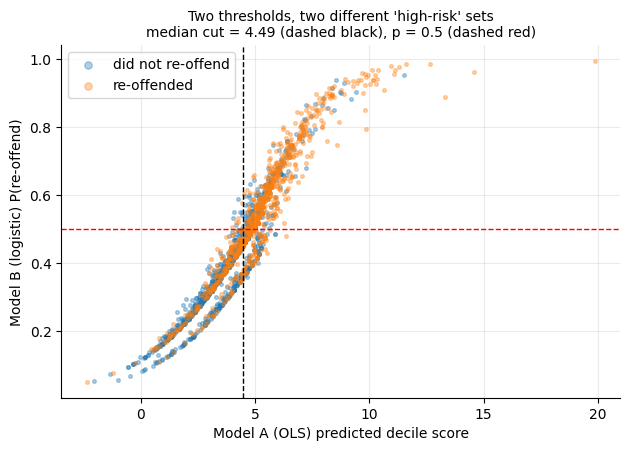

In [3]:
# part 0: train test split
train, test = train_test_split(df, test_size=0.3, random_state=SEED)
train = train.reset_index(drop=True)
test = test.reset_index(drop=True)
R["n_train"] = len(train)
R["n_test"] = len(test)

Xtr = train[FEATS].values.astype(float)
Xte = test[FEATS].values.astype(float)
ytr = train[Y_CLS].values
yte = test[Y_CLS].values

# part 0: feature scaling check
mu = Xtr.mean(0)
sd = Xtr.std(0)
f_raw = logit_fit(Xtr, ytr)
f_std = logit_fit((Xtr - mu) / sd, ytr)
p_raw = logit_predict(f_raw, Xte)
p_std = logit_predict(f_std, (Xte - mu) / sd)
R["scaling_max_prob_diff"] = float(np.abs(p_raw - p_std).max())

sk = LogisticRegression(penalty=None, max_iter=5000).fit((Xtr - mu) / sd, ytr)
R["sklearn_max_prob_diff"] = float(np.abs(sk.predict_proba((Xte - mu) / sd)[:, 1] - p_raw).max())

# part 0: outlier check (cap priors_count at 99th percentile)
cap = np.percentile(train["priors_count"], 99)
Xtr_c = Xtr.copy()
Xte_c = Xte.copy()
Xtr_c[:, 2] = np.minimum(Xtr_c[:, 2], cap)
Xte_c[:, 2] = np.minimum(Xte_c[:, 2], cap)
f_cap = logit_fit(Xtr_c, ytr)

R["cap_value"] = float(cap)
R["acc_uncapped"] = float(((p_raw >= 0.5) == yte).mean())
R["acc_capped"] = float(((logit_predict(f_cap, Xte_c) >= 0.5) == yte).mean())
print("scaling max |dp|:", R["scaling_max_prob_diff"], "| sklearn max |dp|:", R["sklearn_max_prob_diff"], "| acc raw/capped:", R["acc_uncapped"], R["acc_capped"])

# part 1: model A (OLS on decile_score)
Xtr1 = np.column_stack([np.ones(len(Xtr)), Xtr])
Xte1 = np.column_stack([np.ones(len(Xte)), Xte])
betaA = np.linalg.lstsq(Xtr1, train[Y_REG].values, rcond=None)[0]
resid = train[Y_REG].values - Xtr1 @ betaA
s2 = resid @ resid / (len(Xtr1) - Xtr1.shape[1])
seA = np.sqrt(np.diag(s2 * np.linalg.inv(Xtr1.T @ Xtr1)))
predA = Xte1 @ betaA

R["A_r2_test"] = float(1 - np.sum((test[Y_REG] - predA) ** 2) / np.sum((test[Y_REG] - test[Y_REG].mean()) ** 2))
R["A_rmse_test"] = float(np.sqrt(np.mean((test[Y_REG] - predA) ** 2)))

# part 1: model B (logistic on two_year_recid)
fitB = logit_fit(Xtr, ytr)
pB = logit_predict(fitB, Xte)

coef_tbl = pd.DataFrame({
    "feature": ["intercept"] + FEATS,
    "OLS_coef": betaA,
    "OLS_se": seA,
    "Logit_coef": fitB["b"],
    "Logit_se": fitB["se"],
    "Logit_p": fitB["p"],
    "Logit_OR": np.exp(fitB["b"]),
})
coef_tbl.round(4).to_csv("tables/part1_model_coefficients.csv", index=False)
print(coef_tbl.round(4).to_string(index=False))
R["coef_table"] = coef_tbl.round(5).to_dict("records")

# part 1: thresholding and mismatch
medA = float(np.median(predA))
highA = predA >= medA
highB = pB >= 0.5

cm = pd.crosstab(
    pd.Series(np.where(highA, "A: High", "A: Low"), name="Model A (median cut)"),
    pd.Series(np.where(highB, "B: High", "B: Low"), name="Model B (p>=0.5)"),
)
print("\n", cm)

R["cm"] = {
    "AH_BH": int((highA & highB).sum()),
    "AH_BL": int((highA & ~highB).sum()),
    "AL_BH": int((~highA & highB).sum()),
    "AL_BL": int((~highA & ~highB).sum()),
}
R["mismatch_n"] = int((highA != highB).sum())
R["mismatch_pct"] = float(100 * (highA != highB).mean())
R["medA"] = medA
R["A_pred_min"] = float(predA.min())
R["A_pred_max"] = float(predA.max())
R["A_pred_mean"] = float(predA.mean())
R["pB_median"] = float(np.median(pB))
R["pB_mean"] = float(pB.mean())
R["flag_rate_A"] = float(100 * highA.mean())
R["flag_rate_B"] = float(100 * highB.mean())
R["acc_A"] = float((highA == yte).mean())
R["acc_B"] = float((highB == yte).mean())
R["spearman_AB"] = float(stats.spearmanr(predA, pB)[0])
R["pearson_AB"] = float(np.corrcoef(predA, pB)[0, 1])

cutA_matched = np.quantile(predA, 1 - highB.mean())
highA_m = predA >= cutA_matched
R["mismatch_matched_n"] = int((highA_m != highB).sum())
R["mismatch_matched_pct"] = float(100 * (highA_m != highB).mean())
R["cutA_matched"] = float(cutA_matched)

highB_med = pB >= np.median(pB)
R["mismatch_bothmedian_n"] = int((highA != highB_med).sum())
R["mismatch_bothmedian_pct"] = float(100 * (highA != highB_med).mean())
R["test_recid_rate"] = float(yte.mean())

out_of_range = (predA < 1) | (predA > 10)
R["A_out_of_range_n"] = int(out_of_range.sum())
R["A_out_of_range_pct"] = float(100 * out_of_range.mean())

mm = highA != highB
R["mismatch_pB_mean"] = float(pB[mm].mean())
R["mismatch_actual_recid_rate"] = float(yte[mm].mean())
R["mismatch_A_high_B_low_pB_mean"] = float(pB[highA & ~highB].mean())
R["mismatch_A_low_B_high_pB_mean"] = float(pB[~highA & highB].mean())

# part 1: figure 1
fig, ax = plt.subplots(figsize=(6.4, 4.6))
ax.scatter(predA[yte == 0], pB[yte == 0], s=7, alpha=0.35, label="did not re-offend")
ax.scatter(predA[yte == 1], pB[yte == 1], s=7, alpha=0.35, label="re-offended")
ax.axvline(medA, color="k", ls="--", lw=1)
ax.axhline(0.5, color="r", ls="--", lw=1)
ax.set_xlabel("Model A (OLS) predicted decile score")
ax.set_ylabel("Model B (logistic) P(re-offend)")
ax.set_title(f"Two thresholds, two different 'high-risk' sets\nmedian cut = {medA:.2f} (dashed black), p = 0.5 (dashed red)", fontsize=10)
ax.legend(markerscale=2)
plt.tight_layout()
plt.savefig("figures/fig1_threshold_scatter.png")
plt.show()

## Part 2.1 – Simpson's paradox

        feature   full  full_lo  full_hi  full_p      A   A_lo   A_hi   A_p      B   B_lo   B_hi   B_p  diff_A_minus_B  z_diff  p_diff
            age -0.044   -0.049   -0.038   0.000 -0.050 -0.059 -0.042 0.000 -0.036 -0.044 -0.029 0.000          -0.014  -2.466   0.014
       sex_male  0.326    0.185    0.467   0.000  0.522  0.320  0.724 0.000  0.124 -0.074  0.321 0.219           0.399   2.766   0.006
   priors_count  0.163    0.147    0.179   0.000  0.150  0.130  0.170 0.000  0.190  0.161  0.219 0.000          -0.040  -2.238   0.025
  juv_fel_count  0.072   -0.105    0.249   0.427  0.064 -0.140  0.268 0.540  0.041 -0.322  0.403 0.826           0.023   0.110   0.913
 juv_misd_count -0.012   -0.167    0.143   0.878 -0.101 -0.279  0.077 0.266  0.126 -0.180  0.432 0.419          -0.227  -1.258   0.208
juv_other_count  0.274    0.135    0.413   0.000  0.553  0.329  0.778 0.000  0.053 -0.121  0.226 0.552           0.500   3.454   0.001
  charge_felony  0.228    0.113    0.344   0.000  0.187

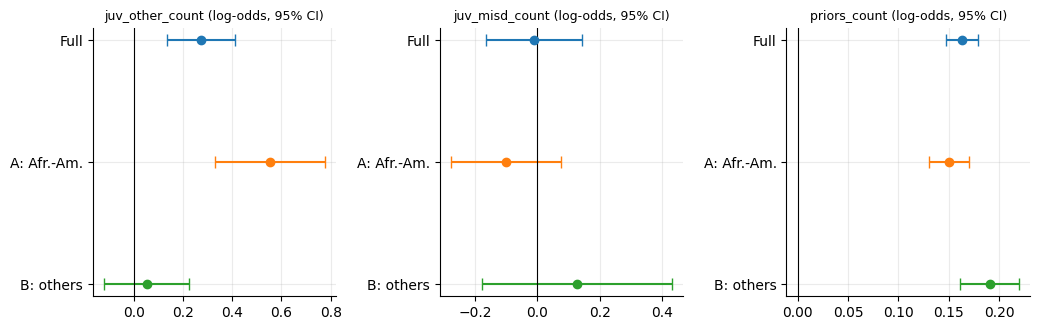

In [4]:
# part 2.1: subgroup logistic regressions (A = African-American, B = all others)
yall = df[Y_CLS].values
fit_full = logit_fit(df[FEATS], yall)
sgA = df[df.race_aa == 1]
sgB = df[df.race_aa == 0]
fit_A = logit_fit(sgA[FEATS], sgA[Y_CLS])
fit_B = logit_fit(sgB[FEATS], sgB[Y_CLS])
R["n_sgA"] = len(sgA)
R["n_sgB"] = len(sgB)

rows = []
for i, c in enumerate(FEATS):
    d = fit_A["b"][i + 1] - fit_B["b"][i + 1]
    zdiff = d / np.hypot(fit_A["se"][i + 1], fit_B["se"][i + 1])
    rows.append(dict(
        feature=c,
        full=fit_full["b"][i + 1], full_lo=fit_full["lo"][i + 1], full_hi=fit_full["hi"][i + 1], full_p=fit_full["p"][i + 1],
        A=fit_A["b"][i + 1], A_lo=fit_A["lo"][i + 1], A_hi=fit_A["hi"][i + 1], A_p=fit_A["p"][i + 1],
        B=fit_B["b"][i + 1], B_lo=fit_B["lo"][i + 1], B_hi=fit_B["hi"][i + 1], B_p=fit_B["p"][i + 1],
        diff_A_minus_B=d,
        z_diff=zdiff,
        p_diff=2 * stats.norm.sf(abs(zdiff)),
    ))

simp = pd.DataFrame(rows)
simp.round(4).to_csv("tables/part2_1_subgroup_coefficients.csv", index=False)
print(simp.round(3).to_string(index=False))
R["simpson"] = simp.round(5).set_index("feature").to_dict("index")

# part 2.1: interaction test for juv_other_count x race
X0 = df[FEATS].assign(race_aa=df.race_aa)
X1 = X0.assign(jo_x_aa=df.juv_other_count * df.race_aa)
f0 = logit_fit(X0, yall)
f1 = logit_fit(X1, yall)
LR = 2 * (f1["ll"] - f0["ll"])
R["interaction"] = dict(
    coef=float(f1["b"][-1]),
    lo=float(f1["lo"][-1]),
    hi=float(f1["hi"][-1]),
    LR=float(LR),
    p=float(stats.chi2.sf(LR, 1)),
)

# part 2.1: screening of all split / predictor pairs (Bonferroni)
df["age_u25"] = (df.age < 25).astype(int)
screen = []
splits = {"sex": "sex_male", "race (AA vs rest)": "race_aa", "age<25": "age_u25", "charge degree": "charge_felony"}
for sname, scol in splits.items():
    fs = [x for x in FEATS if x != scol]
    g1 = df[df[scol] == 1]
    g0 = df[df[scol] == 0]
    ra = logit_fit(g1[fs], g1[Y_CLS])
    rb = logit_fit(g0[fs], g0[Y_CLS])
    for i, k in enumerate(fs):
        zz = (ra["b"][i + 1] - rb["b"][i + 1]) / np.hypot(ra["se"][i + 1], rb["se"][i + 1])
        screen.append((sname, k, float(ra["b"][i + 1]), float(rb["b"][i + 1]), float(zz), float(2 * stats.norm.sf(abs(zz)))))

screen = sorted(screen, key=lambda r: r[5])
R["screen_n_tests"] = len(screen)
R["screen_top"] = screen[:6]
R["race_juvother_bonferroni_p"] = float(min(1, simp.set_index("feature").loc["juv_other_count", "p_diff"] * len(screen)))
print("screened", len(screen), "pairs; top 6:")
for r in screen[:6]:
    print("  ", r)

# part 2.1: raw re-offending rates by juvenile "other" record
R["jo_share_A"] = float(100 * (sgA.juv_other_count > 0).mean())
R["jo_share_B"] = float(100 * (sgB.juv_other_count > 0).mean())
R["jo_rate_A0"] = float(sgA[sgA.juv_other_count == 0][Y_CLS].mean())
R["jo_rate_A1"] = float(sgA[sgA.juv_other_count > 0][Y_CLS].mean())
R["jo_rate_B0"] = float(sgB[sgB.juv_other_count == 0][Y_CLS].mean())
R["jo_rate_B1"] = float(sgB[sgB.juv_other_count > 0][Y_CLS].mean())
R["n_jo_A"] = int((sgA.juv_other_count > 0).sum())
R["n_jo_B"] = int((sgB.juv_other_count > 0).sum())
R["crude_juv_misd"] = float(logit_fit(df[["juv_misd_count"]], yall)["b"][1])

# part 2.1: figure 2
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.4))
for ax, c in zip(axes, ["juv_other_count", "juv_misd_count", "priors_count"]):
    r = simp.set_index("feature").loc[c]
    for k, (lab, key) in enumerate([("Full", "full"), ("A: African-American", "A"), ("B: all others", "B")]):
        ax.errorbar(r[key], k, xerr=[[r[key] - r[key + "_lo"]], [r[key + "_hi"] - r[key]]], fmt="o", capsize=4)
    ax.axvline(0, color="k", lw=0.8)
    ax.set_yticks(range(3))
    ax.set_yticklabels(["Full", "A: Afr.-Am.", "B: others"])
    ax.set_title(c + " (log-odds, 95% CI)", fontsize=9)
    ax.invert_yaxis()
plt.tight_layout()
plt.savefig("figures/fig2_subgroup_coefficients.png")
plt.show()

## Part 2.2 – Omitted variable bias

      predictor  before  after  abs_change  pct_change  shift_in_SE  p_before  p_after
            age  -0.044 -0.028       0.015      34.872        5.580     0.000    0.000
       sex_male   0.326  0.451       0.125      38.423        1.738     0.000    0.000
  juv_fel_count   0.072  0.441       0.369     512.271        4.072     0.427    0.000
 juv_misd_count  -0.012  0.387       0.399    3302.968        5.059     0.878    0.000
juv_other_count   0.274  0.380       0.106      38.604        1.490     0.000    0.000
  charge_felony   0.228  0.409       0.181      79.034        3.068     0.000    0.000
      intercept   0.354  0.067      -0.287     -81.078          NaN     0.002    0.543
{'race_aa': {'before': 0.06322902730280057, 'after': 0.3126492960171582, 'p_before': 0.31807322491036993, 'p_after': 1.982185315476858e-07, 'se_before': 0.06332875821092064}, 'race_hisp': {'before': -0.17448985124095387, 'after': -0.16547164252894242, 'p_before': 0.11082237661695413, 'p_after': 0.115989

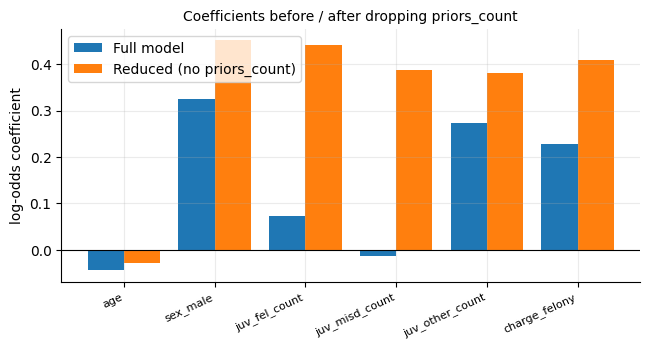

In [5]:
# part 2.2: omitted variable bias (drop priors_count)
RED = [f for f in FEATS if f != "priors_count"]
fit_f = logit_fit(df[FEATS], yall)
fit_r = logit_fit(df[RED], yall)

rows = []
for j, c in enumerate(RED):
    k = FEATS.index(c) + 1
    b0 = fit_f["b"][k]
    b1 = fit_r["b"][j + 1]
    rows.append(dict(
        predictor=c,
        before=b0,
        after=b1,
        abs_change=b1 - b0,
        pct_change=100 * (b1 - b0) / abs(b0),
        shift_in_SE=(b1 - b0) / fit_f["se"][k],
        p_before=fit_f["p"][k],
        p_after=fit_r["p"][j + 1],
    ))

b0 = fit_f["b"][0]
b1 = fit_r["b"][0]
rows.append(dict(
    predictor="intercept",
    before=b0,
    after=b1,
    abs_change=b1 - b0,
    pct_change=100 * (b1 - b0) / abs(b0),
    shift_in_SE=np.nan,
    p_before=fit_f["p"][0],
    p_after=fit_r["p"][0],
))

ovb = pd.DataFrame(rows)
ovb.round(4).to_csv("tables/part2_2_omitted_variable.csv", index=False)
print(ovb.round(3).to_string(index=False))
R["ovb"] = ovb.round(5).to_dict("records")
R["corr_priors"] = {c: float(np.corrcoef(df.priors_count, df[c])[0, 1]) for c in RED}

# part 2.2: test accuracy with and without priors_count
fr_te = logit_fit(train[RED], ytr)
R["acc_full_test"] = R["acc_B"]
R["acc_reduced_test"] = float(((logit_predict(fr_te, test[RED]) >= 0.5) == yte).mean())

# part 2.2: race coefficients with and without priors_count
RACE = ["race_aa", "race_hisp", "race_other"]
full_cols = FEATS + RACE
red_cols = RED + RACE
sf = logit_fit(df[full_cols], yall)
sr = logit_fit(df[red_cols], yall)

R["race_ovb"] = {}
for r in RACE:
    i_full = full_cols.index(r) + 1
    i_red = red_cols.index(r) + 1
    R["race_ovb"][r] = dict(
        before=float(sf["b"][i_full]),
        after=float(sr["b"][i_red]),
        p_before=float(sf["p"][i_full]),
        p_after=float(sr["p"][i_red]),
        se_before=float(sf["se"][i_full]),
    )
print(R["race_ovb"])

# part 2.2: figure 3
fig, ax = plt.subplots(figsize=(6.6, 3.6))
o = ovb[ovb.predictor != "intercept"]
xx = np.arange(len(o))
ax.bar(xx - 0.2, o.before, 0.4, label="Full model")
ax.bar(xx + 0.2, o.after, 0.4, label="Reduced (no priors_count)")
ax.set_xticks(xx)
ax.set_xticklabels(o.predictor, rotation=25, ha="right", fontsize=8)
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("log-odds coefficient")
ax.legend()
ax.set_title("Coefficients before / after dropping priors_count", fontsize=10)
plt.tight_layout()
plt.savefig("figures/fig3_omitted_variable.png")
plt.show()

## Part 2.3 – Adversarial subset

                adversarial_50  full_test
n                        50.00    1852.00
age_mean                 46.88      34.47
age_median               46.50      31.00
pct_male                 80.00      80.45
pct_aa                   56.00      49.62
pct_cauc                 34.00      35.42
priors_mean               6.70       3.15
priors_median             2.00       1.00
pct_priors0              32.00      34.13
pct_priors_le1           44.00      52.81
pct_priors_ge5           42.00      23.38
pct_age_ge30             92.00      56.37
pct_age_lt25              2.00      21.98
pct_age_gt45             52.00      18.90
pct_felony               62.00      64.63
pct_any_juv              20.00      12.80
pct_misd                 38.00      35.37
mean_pB                   0.46       0.46
                 n  observed_rate  mean_pred
priors_count                                
0             1453          0.288      0.342
1              783          0.405      0.393
2-3            811    

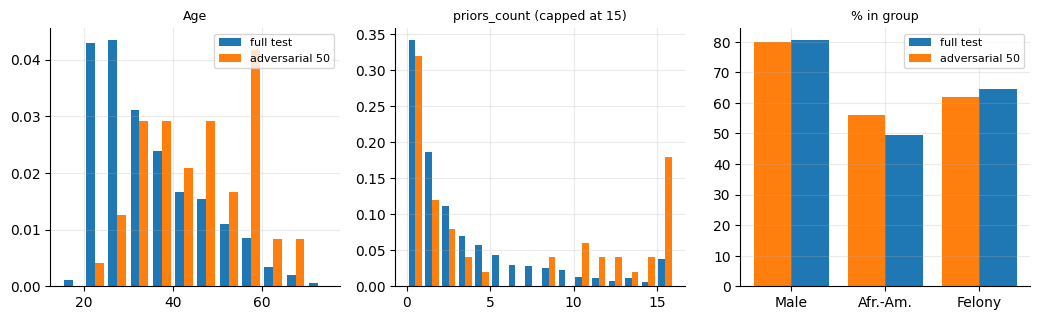

In [6]:
# part 2.3: confident wrong predictions on the test set
test["pB"] = pB
test["pred05"] = (pB >= 0.5).astype(int)

fp_hc = test[(test.pB >= 0.75) & (test[Y_CLS] == 0)]
fn_hc = test[(test.pB <= 0.25) & (test[Y_CLS] == 1)]
hc = pd.concat([
    fp_hc.assign(kind="false positive (p>=.75, y=0)"),
    fn_hc.assign(kind="false negative (p<=.25, y=1)"),
])

n_conf_pos = int((test.pB >= 0.75).sum())
n_conf_neg = int((test.pB <= 0.25).sum())
R["adv"] = dict(
    n_fp=len(fp_hc),
    n_fn=len(fn_hc),
    n_total=len(hc),
    pct_total=100 * len(hc) / len(test),
    n_conf_pos=n_conf_pos,
    n_conf_neg=n_conf_neg,
)
R["adv"]["fp_rate_among_conf_pos"] = 100 * len(fp_hc) / max(1, n_conf_pos)
R["adv"]["fn_rate_among_conf_neg"] = 100 * len(fn_hc) / max(1, n_conf_neg)

# part 2.3: random sample of 50 and its profile
if len(hc) > 50:
    adv = hc.sample(n=min(50, len(hc)), random_state=SEED)
else:
    adv = hc
R["adv"]["n_sample"] = len(adv)
R["adv"]["sample_n_fp"] = int(adv.kind.str.startswith("false positive").sum())
R["adv"]["sample_n_fn"] = int(adv.kind.str.startswith("false negative").sum())


def profile(d):
    return dict(
        n=len(d),
        age_mean=d.age.mean(),
        age_median=d.age.median(),
        pct_male=100 * d.sex_male.mean(),
        pct_aa=100 * d.race_aa.mean(),
        pct_cauc=100 * d.race_cauc.mean(),
        priors_mean=d.priors_count.mean(),
        priors_median=d.priors_count.median(),
        pct_priors0=100 * (d.priors_count == 0).mean(),
        pct_priors_le1=100 * (d.priors_count <= 1).mean(),
        pct_priors_ge5=100 * (d.priors_count >= 5).mean(),
        pct_age_ge30=100 * (d.age >= 30).mean(),
        pct_age_lt25=100 * (d.age < 25).mean(),
        pct_age_gt45=100 * (d.age > 45).mean(),
        pct_felony=100 * d.charge_felony.mean(),
        pct_any_juv=100 * ((d.juv_fel_count + d.juv_misd_count + d.juv_other_count) > 0).mean(),
        pct_misd=100 * (1 - d.charge_felony.mean()),
        mean_pB=d.pB.mean(),
    )


prof = pd.DataFrame({"adversarial_50": profile(adv), "full_test": profile(test)})
prof.round(2).to_csv("tables/part2_3_adversarial_profile.csv")
print(prof.round(2))
R["adv_prof"] = prof.round(4).to_dict()
R["adv_age_cat"] = {
    "adv": adv.age_cat.value_counts(normalize=True).mul(100).round(1).to_dict(),
    "test": test.age_cat.value_counts(normalize=True).mul(100).round(1).to_dict(),
}

# part 2.3: calibration by number of priors
bins = pd.cut(train.priors_count, [-1, 0, 1, 3, 6, 10, 100], labels=["0", "1", "2-3", "4-6", "7-10", "11+"])
cal = pd.DataFrame({
    "n": train.groupby(bins).size(),
    "observed_rate": train.groupby(bins)[Y_CLS].mean(),
    "mean_pred": pd.Series(logit_predict(fitB, Xtr), index=train.index).groupby(bins).mean(),
})
print(cal.round(3))
R["calib_priors"] = cal.round(4).reset_index().astype({"priors_count": str}).to_dict("records")


# part 2.3: likelihood ratio tests for missing terms
def lr_test(extra_cols):
    Xb = train[FEATS].copy()
    Xe = Xb.copy()
    for k, v in extra_cols.items():
        Xe[k] = v
    a = logit_fit(Xb, ytr)
    b = logit_fit(Xe, ytr)
    s = 2 * (b["ll"] - a["ll"])
    return dict(
        LR=float(s),
        p=float(stats.chi2.sf(s, len(extra_cols))),
        coef=[float(x) for x in b["b"][-len(extra_cols):]],
    )


R["lr_age_x_priors"] = lr_test({"age_x_priors": train.age * train.priors_count})
R["lr_priors_sq"] = lr_test({"priors_sq": train.priors_count ** 2})
R["lr_priors_log"] = lr_test({"log_priors": np.log1p(train.priors_count)})
R["lr_sex_x_priors"] = lr_test({"sex_x_priors": train.sex_male * train.priors_count})

# part 2.3: observed rates inside the confident regions
low_conf = test[test.pB <= 0.25]
high_conf = test[test.pB >= 0.75]
R["adv"]["obs_rate_p_le_25"] = float(100 * low_conf[Y_CLS].mean())
R["adv"]["mean_p_le_25"] = float(low_conf.pB.mean())
R["adv"]["obs_rate_p_ge_75"] = float(100 * high_conf[Y_CLS].mean())
R["adv"]["mean_p_ge_75"] = float(high_conf.pB.mean())
R["adv"]["p_max"] = float(test.pB.max())

# part 2.3: a typical defendant with no priors
typ = dict(age=40, sex_male=1, priors_count=0, juv_fel_count=0, juv_misd_count=0, juv_other_count=0, charge_felony=1)
R["typ_p_nopriors_40"] = float(logit_predict(fitB, np.array([[typ[k] for k in FEATS]]))[0])
no_priors_30 = test[(test.priors_count == 0) & (test.age >= 30)]
R["recid_rate_priors0_age30plus"] = float(no_priors_30[Y_CLS].mean())
R["n_priors0_age30plus"] = int(len(no_priors_30))

R["adv_by_kind"] = {}
for k, g in adv.groupby("kind"):
    R["adv_by_kind"][k] = dict(
        n=int(len(g)),
        age_mean=float(g.age.mean()),
        priors_mean=float(g.priors_count.mean()),
        priors_median=float(g.priors_count.median()),
        pct_age_ge30=float(100 * (g.age >= 30).mean()),
        pct_age_gt45=float(100 * (g.age > 45).mean()),
        pct_priors0=float(100 * (g.priors_count == 0).mean()),
    )

R["adv_by_kind_full"] = {}
for k, g in hc.groupby("kind"):
    R["adv_by_kind_full"][k] = dict(
        n=int(len(g)),
        pct_age_ge30=float(100 * (g.age >= 30).mean()),
        age_mean=float(g.age.mean()),
        priors_mean=float(g.priors_count.mean()),
    )

# part 2.3: calibration by age band
age_labels = ["<25", "25-29", "30-44", "45+"]
age_edges = [0, 24, 29, 44, 200]
ab = pd.cut(test.age, age_edges, labels=age_labels)
agecal = pd.DataFrame({
    "n": test.groupby(ab).size(),
    "observed": test.groupby(ab)[Y_CLS].mean(),
    "mean_pred": test.groupby(ab).pB.mean(),
    "share_of_high_conf_errors": hc.groupby(pd.cut(hc.age, age_edges, labels=age_labels)).size() / len(hc),
})
print(agecal.round(3))
R["agecal"] = agecal.round(4).reset_index().astype({"age": str}).to_dict("records")

# part 2.3: confident error rate for ages 30+ vs under 30
for nm, msk in {"age>=30": test.age >= 30, "age<30": test.age < 30}.items():
    d = test[msk]
    cp = d[d.pB >= 0.75]
    cn = d[d.pB <= 0.25]
    n_conf = len(cp) + len(cn)
    n_wrong = int((cp[Y_CLS] == 0).sum()) + int((cn[Y_CLS] == 1).sum())
    R["adv"]["err_" + nm] = dict(
        n_conf=int(n_conf),
        n_wrong=int(n_wrong),
        pct_wrong=float(100 * n_wrong / max(1, n_conf)),
    )
print(R["adv"]["err_age>=30"], R["adv"]["err_age<30"])

# part 2.3: figure 4
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.3))
axes[0].hist([test.age, adv.age], bins=np.arange(15, 80, 5), density=True, label=["full test", "adversarial 50"])
axes[0].set_title("Age", fontsize=9)
axes[0].legend(fontsize=8)

axes[1].hist([test.priors_count.clip(upper=15), adv.priors_count.clip(upper=15)], bins=np.arange(0, 17, 1), density=True, label=["full test", "adversarial 50"])
axes[1].set_title("priors_count (capped at 15)", fontsize=9)

groups = ["Male", "Afr.-Am.", "Felony"]
axes[2].bar(groups, [100 * test.sex_male.mean(), 100 * test.race_aa.mean(), 100 * test.charge_felony.mean()], 0.4, label="full test", align="edge")
axes[2].bar(groups, [100 * adv.sex_male.mean(), 100 * adv.race_aa.mean(), 100 * adv.charge_felony.mean()], -0.4, label="adversarial 50", align="edge")
axes[2].set_title("% in group", fontsize=9)
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.savefig("figures/fig4_adversarial_profile.png")
plt.show()

## Part 2.4 – Fairness trade-off

   t    DP    EO    PP  sel_A  sel_B  TPR_A  TPR_B  FPR_A  FPR_B  PPV_A  PPV_B  acc_all
0.05 1.000 1.000 0.749  1.000  1.000  1.000  1.000  1.000  1.000  0.373  0.498    0.437
0.15 0.946 0.932 0.771  0.939  0.992  0.971  0.998  0.920  0.987  0.386  0.501    0.457
0.25 0.838 0.804 0.815  0.780  0.931  0.882  0.967  0.720  0.896  0.422  0.518    0.517
0.35 0.746 0.730 0.830  0.602  0.807  0.759  0.919  0.509  0.696  0.471  0.567    0.604
0.45 0.615 0.651 0.819  0.372  0.605  0.522  0.777  0.282  0.434  0.525  0.640    0.666
0.55 0.464 0.507 0.819  0.166  0.358  0.273  0.539  0.102  0.178  0.615  0.751    0.677
0.65 0.343 0.293 0.982  0.078  0.226  0.159  0.354  0.029  0.100  0.765  0.779    0.646
0.75 0.280 0.160 1.064  0.035  0.125  0.082  0.205  0.007  0.046  0.870  0.817    0.613
0.85 0.350 0.374 0.930  0.020  0.057  0.041  0.094  0.007  0.020  0.769  0.827    0.588
0.95 0.255 0.000 1.100  0.003  0.012  0.008  0.022  0.000  0.002  1.000  0.909    0.570
{'t1': 0.45, 't2': 0.65, 'DP': (

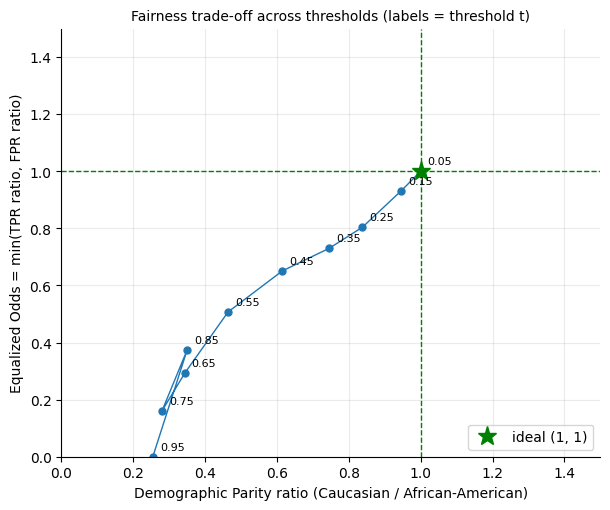

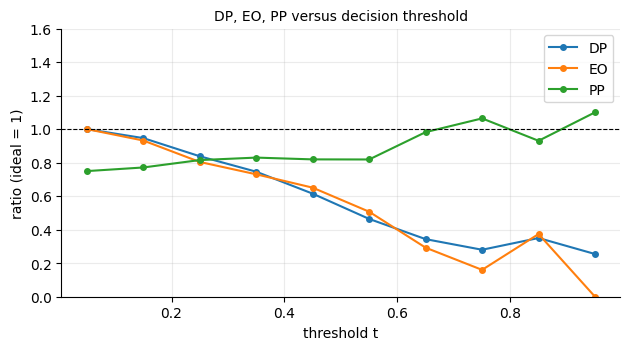

In [7]:
# part 2.4: groups (A = Caucasian, B = African-American) on the test set
tg = test[test.race.isin(["Caucasian", "African-American"])].copy()
ga = tg[tg.race == "Caucasian"]
gb = tg[tg.race == "African-American"]
R["fair_n"] = dict(
    A=len(ga),
    B=len(gb),
    A_recid=float(ga[Y_CLS].mean()),
    B_recid=float(gb[Y_CLS].mean()),
    A_meanp=float(ga.pB.mean()),
    B_meanp=float(gb.pB.mean()),
)


def rates(d, t):
    yh = (d.pB >= t).astype(int)
    y = d[Y_CLS]
    n1 = int(yh.sum())
    tpr = ((yh == 1) & (y == 1)).sum() / max(1, (y == 1).sum())
    fpr = ((yh == 1) & (y == 0)).sum() / max(1, (y == 0).sum())
    ppv = ((yh == 1) & (y == 1)).sum() / n1 if n1 else np.nan
    return dict(sel=yh.mean(), tpr=tpr, fpr=fpr, ppv=ppv, n_flag=n1, acc=(yh == y).mean())


def ratio(a, b):
    if np.isnan(a) or np.isnan(b) or b == 0:
        return np.nan
    return a / b


# part 2.4: DP, EO and PP over thresholds
sweep = []
for t in np.round(np.arange(0.05, 0.96, 0.10), 2):
    a = rates(ga, t)
    b = rates(gb, t)
    both = ((tg.pB >= t).astype(int) == tg[Y_CLS]).mean()

    dp = ratio(a["sel"], b["sel"])
    eo_t = ratio(a["tpr"], b["tpr"])
    eo_f = ratio(a["fpr"], b["fpr"])
    if np.isnan(eo_t) and np.isnan(eo_f):
        eo = np.nan
    else:
        eo = np.nanmin([eo_t, eo_f])
    pp = ratio(a["ppv"], b["ppv"])

    sweep.append(dict(
        t=t, DP=dp, EO=eo, PP=pp, TPR_ratio=eo_t, FPR_ratio=eo_f,
        sel_A=a["sel"], sel_B=b["sel"],
        TPR_A=a["tpr"], TPR_B=b["tpr"],
        FPR_A=a["fpr"], FPR_B=b["fpr"],
        PPV_A=a["ppv"], PPV_B=b["ppv"],
        nflag_A=a["n_flag"], nflag_B=b["n_flag"],
        acc_AB=both,
        acc_all=((test.pB >= t).astype(int) == test[Y_CLS]).mean(),
    ))

sw = pd.DataFrame(sweep)
sw.round(4).to_csv("tables/part2_4_fairness_sweep.csv", index=False)
cols = ["t", "DP", "EO", "PP", "sel_A", "sel_B", "TPR_A", "TPR_B", "FPR_A", "FPR_B", "PPV_A", "PPV_B", "acc_all"]
print(sw[cols].round(3).to_string(index=False))
R["sweep"] = sw.round(5).to_dict("records")


# part 2.4: trade-off between thresholds
def pc(a, b):
    return 100 * (b - a) / a


def tradeoff(t1, t2):
    r1 = sw[sw.t == t1].iloc[0]
    r2 = sw[sw.t == t2].iloc[0]
    return dict(
        t1=t1,
        t2=t2,
        DP=(r1.DP, r2.DP, pc(r1.DP, r2.DP)),
        EO=(r1.EO, r2.EO, pc(r1.EO, r2.EO)),
        PP=(r1.PP, r2.PP, pc(r1.PP, r2.PP)),
        acc=(r1.acc_all, r2.acc_all, pc(r1.acc_all, r2.acc_all)),
    )


R["trade_up"] = tradeoff(0.45, 0.65)
R["trade_down"] = tradeoff(0.45, 0.25)
R["trade_up"]["cost_EO_per_PP"] = -R["trade_up"]["EO"][2] / R["trade_up"]["PP"][2]
R["trade_up"]["cost_DP_per_PP"] = -R["trade_up"]["DP"][2] / R["trade_up"]["PP"][2]
R["trade_down"]["cost_acc_per_DP"] = -R["trade_down"]["acc"][2] / R["trade_down"]["DP"][2]
R["trade_down"]["cost_acc_per_EO"] = -R["trade_down"]["acc"][2] / R["trade_down"]["EO"][2]
print(R["trade_up"])
print(R["trade_down"])

sw["worst_of_3"] = sw[["DP", "EO", "PP"]].min(axis=1)
print(sw[["t", "worst_of_3", "acc_all"]].round(3).T.to_string())

# part 2.4: two real defendants for the Q6 example
c1 = tg[(tg.race == "African-American") & (tg[Y_CLS] == 0) & (tg.pB >= 0.45) & (tg.pB < 0.55)]
c2 = tg[(tg.race == "Caucasian") & (tg[Y_CLS] == 0) & (tg.pB < 0.45) & (tg.pB >= 0.30)]

best = None
for i, r1 in c1.iterrows():
    for j, r2 in c2.iterrows():
        if r1.sex_male == r2.sex_male and abs(r1.age - r2.age) <= 2 and r1.priors_count > r2.priors_count:
            key = (abs(r1.age - r2.age), -(r1.priors_count - r2.priors_count), i, j)
            if best is None or key < best[0]:
                best = (key, i, j)

_, ia, ib = best
aa_person = tg.loc[ia]
cauc_person = tg.loc[ib]


def person(r):
    return dict(
        id=int(r["id"]),
        race=r.race,
        sex=r.sex,
        age=int(r.age),
        priors=int(r.priors_count),
        juv=int(r.juv_fel_count + r.juv_misd_count + r.juv_other_count),
        charge=r.c_charge_degree,
        p=float(r.pB),
        recid=int(r[Y_CLS]),
    )


R["scenario"] = dict(person_B=person(aa_person), person_A=person(cauc_person))
print(R["scenario"])
for t in [0.35, 0.45, 0.55, 0.65]:
    print(t, "AA person flagged:", aa_person.pB >= t, "| Caucasian person flagged:", cauc_person.pB >= t)

# part 2.4: figure 5
fig, ax = plt.subplots(figsize=(6.2, 5.2))
ok = sw.dropna(subset=["DP", "EO"])
ax.plot(ok.DP, ok.EO, "-o", color="tab:blue", ms=5, lw=1)
for _, r in ok.iterrows():
    ax.annotate(f"{r.t:.2f}", (r.DP, r.EO), textcoords="offset points", xytext=(5, 5), fontsize=8)
ax.axvline(1, color="g", ls="--", lw=1)
ax.axhline(1, color="g", ls="--", lw=1)
ax.plot([1], [1], "g*", ms=14, label="ideal (1, 1)")
ax.set_xlim(0, 1.5)
ax.set_ylim(0, 1.5)
ax.set_xlabel("Demographic Parity ratio (Caucasian / African-American)")
ax.set_ylabel("Equalized Odds = min(TPR ratio, FPR ratio)")
ax.legend(loc="lower right")
ax.set_title("Fairness trade-off across thresholds (labels = threshold t)", fontsize=10)
plt.tight_layout()
plt.savefig("figures/fig5_tradeoff_chart.png")
plt.show()

# part 2.4: figure 6
fig, ax = plt.subplots(figsize=(6.4, 3.6))
for m in ["DP", "EO", "PP"]:
    ax.plot(sw.t, sw[m], "-o", ms=4, label=m)
ax.axhline(1, color="k", lw=0.8, ls="--")
ax.set_xlabel("threshold t")
ax.set_ylabel("ratio (ideal = 1)")
ax.set_ylim(0, 1.6)
ax.legend()
ax.set_title("DP, EO, PP versus decision threshold", fontsize=10)
plt.tight_layout()
plt.savefig("figures/fig6_metrics_vs_threshold.png")
plt.show()

## Save results

In [8]:
# save all results to results.json
def clean(o):
    if isinstance(o, dict):
        return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [clean(v) for v in o]
    if isinstance(o, (np.floating, float)):
        return None if np.isnan(o) else float(o)
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.bool_):
        return bool(o)
    return o


json.dump(clean(R), open("results.json", "w"), indent=1)
print("saved results.json; figures/ and tables/ written")

saved results.json; figures/ and tables/ written